In [38]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

def average_queue_counts(queue_count_times, queue_counts):
    # Remove padding
    times = [
        np.asarray(t)[np.isfinite(t)]
        for t in queue_count_times
    ]

    counts = [
        np.asarray(c)[np.isfinite(c)]
        for c in queue_counts
    ]

    # Create common timeline from all event times
    time_grid = np.unique(np.concatenate(times))

    # Evaluate each replication at every point in the timeline
    replication_counts = np.full(
        (len(times), len(time_grid)),
        np.nan
    )

    for i, (t, c) in enumerate(zip(times, counts)):
        # Find most recent event at each time
        indices = np.searchsorted(t, time_grid, side='right') - 1

        valid = indices >= 0

        replication_counts[i, valid] = c[indices[valid]]

    # Calculate statistics across replications
    mean_counts = np.nanmean(replication_counts, axis=0)
    std_counts = np.nanstd(replication_counts, axis=0)

    return time_grid, mean_counts, std_counts

In [40]:
def create_plots(run_path: str):
    run = np.load(Path("runs") / run_path)

    # Load queue count data
    queue_count_times = run['queue_count_times']
    queue_counts = run['queue_counts']

    # Calculate average queue counts
    time_grid, mean_counts, std_counts = average_queue_counts(
        queue_count_times,
        queue_counts
    )

    # Plot
    plt.figure(figsize=(10, 5))

    plt.step(
        time_grid,
        mean_counts,
        where='post',
        label='Mean queue length'
    )

    plt.fill_between(
        time_grid,
        mean_counts - std_counts,
        mean_counts + std_counts,
        step='post',
        alpha=0.2,
        label='±1 standard deviation'
    )

    plt.xlabel('Simulation time')
    plt.ylabel('Queue length')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

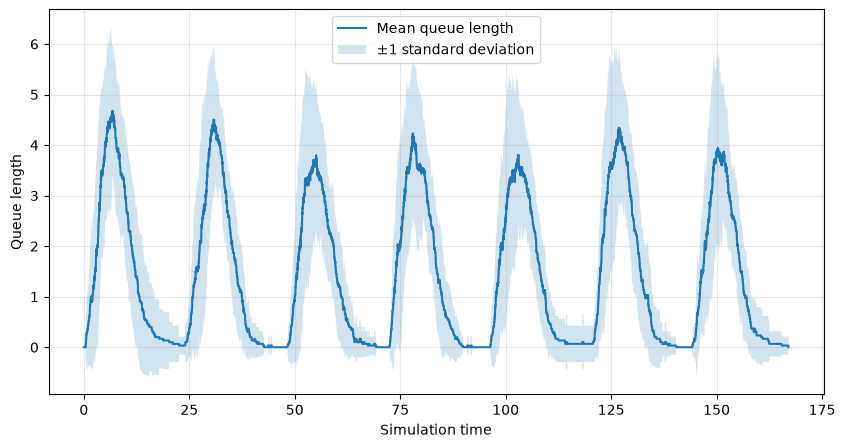

In [42]:
run = "20261113-142521.npz"

create_plots(run)